In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

In [49]:
df = pd.read_csv("ram.csv")
def convert_to_mb(val):
    val = str(val).lower().strip()
    
    if "gb" in val:
        return float(val.replace("gb", "")) * 1024
    elif "g" in val:
        return float(val.replace("g", "")) * 1024
    elif "mb" in val:
        return float(val.replace("mb", ""))
    elif "m" in val:
        return float(val.replace("m", ""))
    else:
        return float(val)  # fallback if already numeric

# apply conversions
df["device_write"] = df["device_write"].apply(convert_to_mb)
df["memory"] = df["memory"].apply(convert_to_mb)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ArrivalRate   1215 non-null   int64  
 1   device_write  1215 non-null   float64
 2   cpus          1215 non-null   float64
 3   memory        1215 non-null   float64
 4   cpuLoad       1215 non-null   int64  
 5   size          1215 non-null   int64  
 6   Throughput    1215 non-null   float64
 7   ResponseTime  1215 non-null   float64
dtypes: float64(5), int64(3)
memory usage: 76.1 KB


In [50]:
# --- CLEANING STEP 1: Remove zero/near-zero ResponseTime rows ---
# These are measurement failures or idle states — cause div/0 in MAPE.
n_before = len(df)
df = df[df['ResponseTime'] > 0].copy()
print(f'Removed {n_before - len(df)} rows with ResponseTime <= 0')

# --- CLEANING STEP 1b: Handle extreme high-RT outliers ---
# Strategy: remove anything above BOTH the 99th percentile AND 100,000 ms.
# Use the stricter (lower) of the two thresholds so we don't over-remove.
# Rows below the cap but still high are winsorized (clamped) rather than
# dropped, preserving saturation signal without letting outliers dominate.
p99 = df['ResponseTime'].quantile(0.995)
hard_cap = 120000  # ms
remove_threshold = min(p99, hard_cap)

n_before = len(df)
df = df[df['ResponseTime'] <= remove_threshold].copy()
n_removed = n_before - len(df)

# Winsorize: clamp anything above the 95th pct to that value
# (softens the influence of near-extreme rows without dropping them)
p95 = df['ResponseTime'].quantile(0.95)
df['ResponseTime'] = df['ResponseTime'].clip(upper=p95)

print(f'99th percentile RT: {p99:.1f} ms')
print(f'Hard cap:           {hard_cap} ms')
print(f'Remove threshold:   {remove_threshold:.1f} ms (stricter of the two)')
print(f'Rows removed:       {n_removed}')
print(f'Winsorize cap (p95):{p95:.1f} ms')

# --- CLEANING STEP 2: Drop constant / near-constant columns ---
# Check variance of each column
print('\nColumn value counts (unique):')
for col in df.columns:
    print(f'  {col}: {df[col].nunique()} unique values')

# Drop columns with only 1 unique value (no predictive power)
cols_to_drop = [col for col in df.columns if df[col].nunique() == 1]
print(f'\nDropping constant columns: {cols_to_drop}')
df.drop(columns=cols_to_drop, inplace=True)

# --- CLEANING STEP 3: Drop Throughput (target leakage) ---
# Throughput is determined simultaneously with ResponseTime (Little's Law).
# Keeping it inflates scores but makes the model useless for real inference.
if 'Throughput' in df.columns:
    df.drop(columns=['Throughput'], inplace=True)
    print('Dropped Throughput (target leakage)')

print(f'\nFinal shape: {df.shape}')
print('Remaining features:', list(df.columns))

Removed 0 rows with ResponseTime <= 0
99th percentile RT: 169534.8 ms
Hard cap:           120000 ms
Remove threshold:   120000.0 ms (stricter of the two)
Rows removed:       17
Winsorize cap (p95):48169.6 ms

Column value counts (unique):
  ArrivalRate: 5 unique values
  device_write: 3 unique values
  cpus: 3 unique values
  memory: 3 unique values
  cpuLoad: 3 unique values
  size: 3 unique values
  Throughput: 281 unique values
  ResponseTime: 776 unique values

Dropping constant columns: []
Dropped Throughput (target leakage)

Final shape: (1198, 7)
Remaining features: ['ArrivalRate', 'device_write', 'cpus', 'memory', 'cpuLoad', 'size', 'ResponseTime']


In [51]:
X = df[["ArrivalRate", "device_write", "cpus", "memory", "cpuLoad", "size"]]
y = df["ResponseTime"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# y_log = np.log1p(y)

In [52]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

In [63]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rf = RandomForestRegressor(
    n_estimators=2000,
    max_depth=8,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# inverse transform
# y_pred_rf = np.expm1(y_pred_rf)
# y_test_actual = np.expm1(y_test)

In [54]:
svr = SVR(kernel='rbf')
svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)

In [55]:
mlp = MLPRegressor(hidden_layer_sizes=(64,64), max_iter=500, random_state=42)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [56]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def smape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    return np.mean(
        2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-6)) * 100

def p90_error(y_true, y_pred):
    errors = np.abs((y_true - y_pred) / y_true) * 100
    return np.percentile(errors, 90)

In [64]:
models = {
    "Linear": y_pred_lr,
    "RandomForest": y_pred_rf,
    "SVR": y_pred_svr,
    "MLP": y_pred_mlp
}

for name, pred in models.items():
    print(name)
    print("MAPE:", mape(y_test, pred))
    print("P90 Error:", p90_error(y_test, pred))
    print("SNAPE:", smape(y_test, pred))
    print("------")

Linear
MAPE: 48532.66185558264
P90 Error: 176590.31821622644
SNAPE: 122.83427911197448
------
RandomForest
MAPE: 19716.530704299137
P90 Error: 34918.835193341394
SNAPE: 111.35618085534806
------
SVR
MAPE: 12066.778470546173
P90 Error: 36413.05394593233
SNAPE: 148.85775397981234
------
MLP
MAPE: 25313.81896542647
P90 Error: 91391.79081733218
SNAPE: 123.92369889586546
------


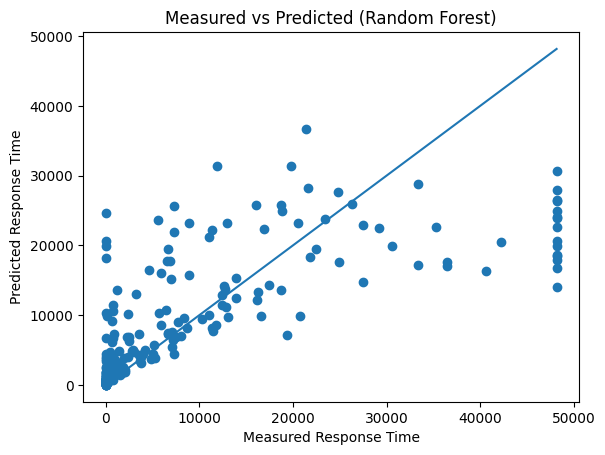

In [58]:
plt.scatter(y_test, y_pred_rf)
plt.xlabel("Measured Response Time")
plt.ylabel("Predicted Response Time")
plt.title("Measured vs Predicted (Random Forest)")

plt.plot([min(y_test), max(y_test)],
         [min(y_test), max(y_test)])

plt.show()

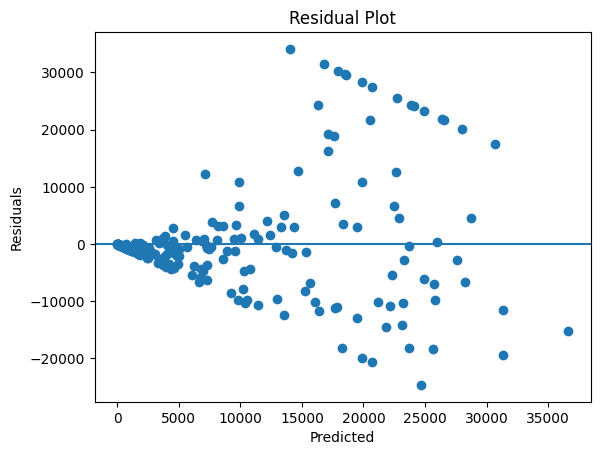

In [59]:
residuals = y_test - y_pred_rf

plt.scatter(y_pred_rf, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

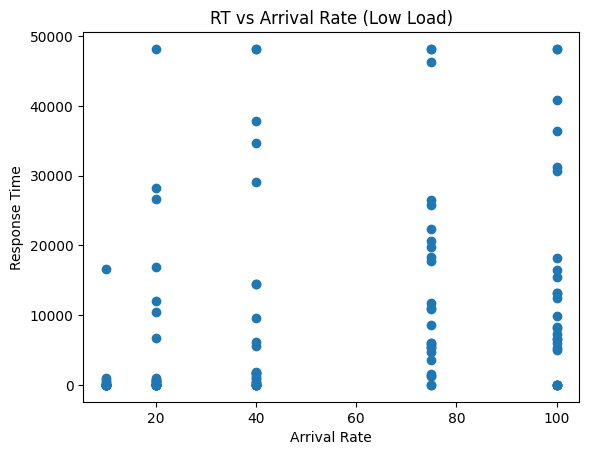

In [60]:
subset = df[(df["cpuLoad"] == 0) & (df["size"] == 0)]

# plt.plot(subset["ArrivalRate"], subset["ResponseTime"], 'o-')
plt.scatter(subset["ArrivalRate"], subset["ResponseTime"])
plt.xlabel("Arrival Rate")
plt.ylabel("Response Time")
plt.title("RT vs Arrival Rate (Low Load)")
plt.show()

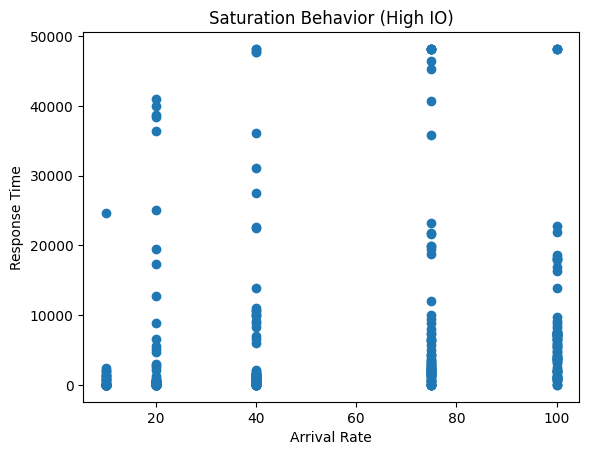

In [61]:
subset = df[(df["size"] == 1000)]

plt.scatter(subset["ArrivalRate"], subset["ResponseTime"])
plt.xlabel("Arrival Rate")
plt.ylabel("Response Time")
plt.title("Saturation Behavior (High IO)")
plt.show()

In [62]:
subset = df[df["size"] == 1000]

plt.scatter(subset["ArrivalRate"], subset["Throughput"])
plt.xlabel("Arrival Rate")
plt.ylabel("Throughput")
plt.title("Throughput Collapse at High Load")
plt.show()

KeyError: 'Throughput'

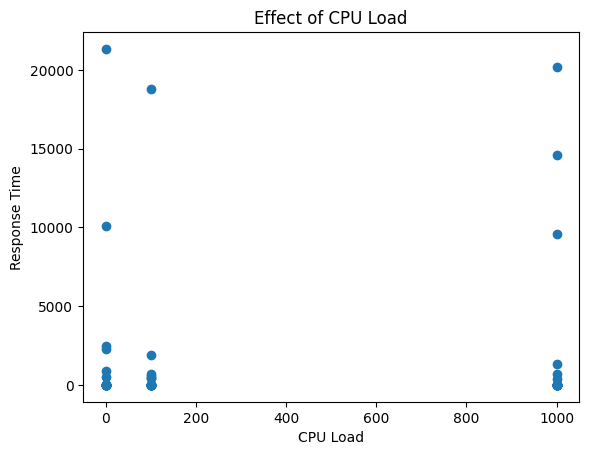

In [ ]:
subset = df[(df["ArrivalRate"] == 10) & (df["size"] == 250)]

plt.scatter(subset["cpuLoad"], subset["ResponseTime"])
plt.xlabel("CPU Load")
plt.ylabel("Response Time")
plt.title("Effect of CPU Load")
plt.show()

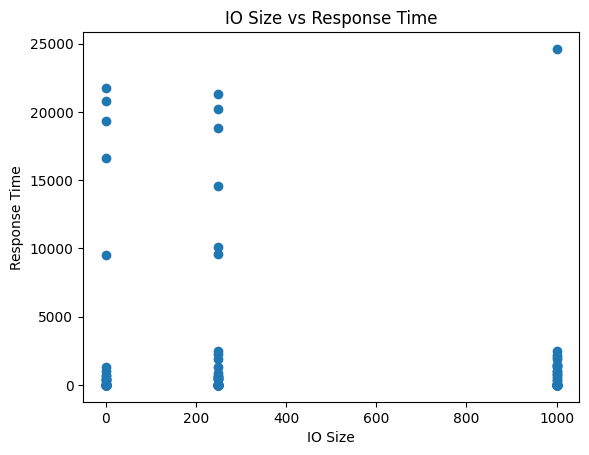

In [ ]:
subset = df[(df["ArrivalRate"] == 10)]

plt.scatter(subset["size"], subset["ResponseTime"])
plt.xlabel("IO Size")
plt.ylabel("Response Time")
plt.title("IO Size vs Response Time")
plt.show()

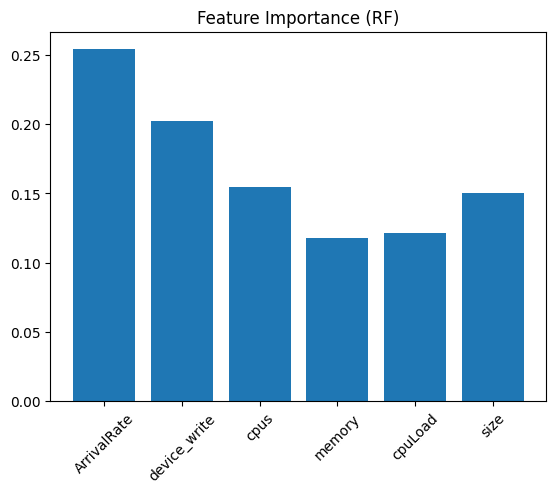

In [ ]:
importances = rf.feature_importances_

features = X.columns

plt.bar(features, importances)
plt.xticks(rotation=45)
plt.title("Feature Importance (RF)")
plt.show()

In [ ]:
sample = [[10, 20, 0.5, 256, 100, 250]]

print("Predicted RT:", rf.predict(sample))

Predicted RT: [4.204]


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Arrival Rate: 10 -> Predicted RT: 4.2 ms
Arrival Rate: 20 -> Predicted RT: 355.2 ms
Arrival Rate: 30 -> Predicted RT: 355.2 ms
Arrival Rate: 40 -> Predicted RT: 1554.0 ms
Arrival Rate: 50 -> Predicted RT: 1554.0 ms
Arrival Rate: 60 -> Predicted RT: 9303.9 ms
Arrival Rate: 70 -> Predicted RT: 9303.9 ms
Arrival Rate: 80 -> Predicted RT: 9303.9 ms
Arrival Rate: 90 -> Predicted RT: 15231.9 ms
Arrival Rate: 100 -> Predicted RT: 15231.9 ms


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/l

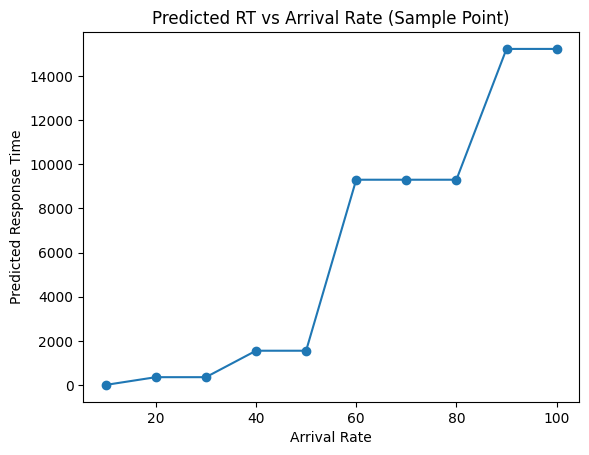

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/l

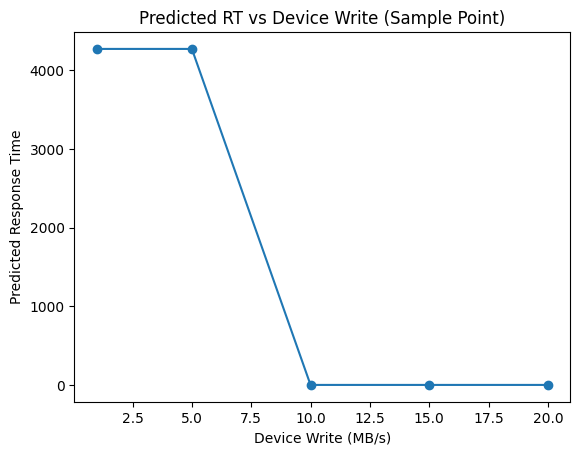

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


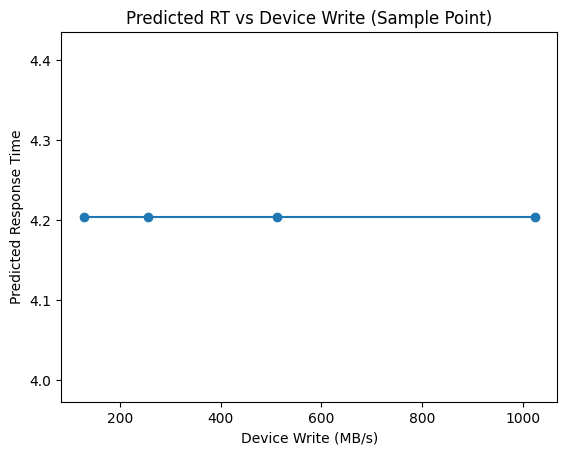

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


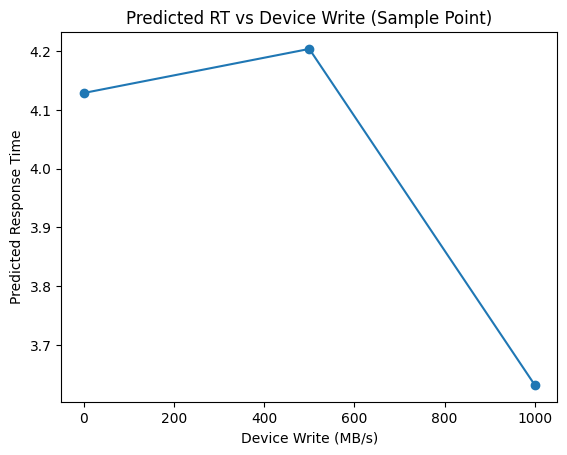

In [ ]:
preds = []
i_range = [10*i for i in range(1, 11)] 
for i in i_range:
    sample[0][0] = i
    print(f"Arrival Rate: {i} -> Predicted RT: {rf.predict(sample)[0]:.1f} ms")
    preds.append(rf.predict(sample)[0])

plt.plot(i_range, preds, 'o-')
plt.xlabel("Arrival Rate")
plt.ylabel("Predicted Response Time")
plt.title("Predicted RT vs Arrival Rate (Sample Point)")
plt.show()

sample = [[10, 20, 0.5, 256, 100, 250]]
preds = []
dev_write_range = [1, 5, 10, 15, 20]
plt.plot(dev_write_range, [rf.predict([[10, dw, 0.5, 256, 100, 250]])[0] for dw in dev_write_range], 'o-')
plt.xlabel("Device Write (MB/s)")
plt.ylabel("Predicted Response Time")
plt.title("Predicted RT vs Device Write (Sample Point)")
plt.show()

sample = [[10, 20, 0.5, 256, 100, 250]]
preds = []
memory_range = [128, 256, 512, 1024]
plt.plot(memory_range, [rf.predict([[10, dw, 0.5, 256, 500, 250]])[0] for dw in memory_range], 'o-')
plt.xlabel("Device Write (MB/s)")
plt.ylabel("Predicted Response Time")
plt.title("Predicted RT vs Device Write (Sample Point)")
plt.show()

sample = [[10, 20, 0.5, 256, 100, 250]]
preds = []
memory_range = [0, 500, 1000]
plt.plot(memory_range, [rf.predict([[10, 20, 0.5, 256, 500, dw]])[0] for dw in memory_range], 'o-')
plt.xlabel("Device Write (MB/s)")
plt.ylabel("Predicted Response Time")
plt.title("Predicted RT vs Device Write (Sample Point)")
plt.show()